In [1]:
# SETUP AND LOAD DATA
from pathlib import Path
import pandas as pd
import numpy as np

# Project structure:
# nyc-airbnb-data-management/
# ├── Airbnb/
# │   └── Airbnb_NYC_2019_RAW.csv
# └── notebooks/
#     └── 01_data_quality_profiling.ipynb

AIRBNB_DIR = Path("../Airbnb")

# Find the raw Airbnb CSV
raw_files = list(AIRBNB_DIR.glob("Airbnb_NYC_2019_RAW*.csv"))

if not raw_files:
    raise FileNotFoundError(
        f"No raw Airbnb CSV found in: {AIRBNB_DIR.resolve()}"
    )

RAW_FILE = raw_files[0]

print("Using dataset:")
print(RAW_FILE)

# Load dataset
df = pd.read_csv(RAW_FILE)

# Show first rows
df.head()

Using dataset:
../Airbnb/Airbnb_NYC_2019_RAW.csv


/var/folders/8v/frb1qkxn6tvb4c7lz7kfr90r0000gn/T/ipykernel_11860/2001901656.py:29: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(RAW_FILE)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [2]:
#BASIC DATASET CHECK
# Dataset shape
print("Rows and columns:", df.shape)

# Column names
print(df.columns)

# Basic info
df.info()

Rows and columns: (48895, 16)
Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64


In [3]:
#MISSING VALUES TABLE
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
})

missing_table = missing_table[missing_table["Missing Count"] > 0]
missing_table.sort_values(by="Missing Count", ascending=False)



,Missing Count,Missing Percentage
last_review,10052,20.558339
reviews_per_month,10052,20.558339
host_name,21,0.042949
name,16,0.032723


In [4]:
#DUPLICATE CHECK 
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["id"].duplicated().sum()

print("Exact duplicate rows:", duplicate_rows)
print("Duplicate listing IDs:", duplicate_ids)

Exact duplicate rows: 0
Duplicate listing IDs: 0


In [5]:
df.shape
df.info()
missing_table
duplicate_rows
duplicate_ids
df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count     object
availability_365                    int64
dtype: object

In [6]:
#STATISTICAL PROFILING
# Summary statistics
df.describe(include='all')

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,48879,4.889500e+04,48874,48895,48895,48895.000000,48895.000000,48895,48895.000000,48895.000000,48895.000000,38843,38843.000000,48895,48895.000000
unique,NaN,47904,NaN,11452,5,221,NaN,NaN,3,NaN,NaN,NaN,1764,NaN,86,NaN
top,NaN,Hillside Hotel,NaN,Michael,Manhattan,Williamsburg,NaN,NaN,Entire home/apt,NaN,NaN,NaN,2019-06-23,NaN,1,NaN
freq,NaN,18,NaN,417,21661,3920,NaN,NaN,25409,NaN,NaN,NaN,1413,NaN,22969,NaN
mean,1.901714e+07,NaN,6.762001e+07,NaN,NaN,NaN,40.728949,-73.952170,NaN,152.720687,7.029962,23.274466,NaN,1.373221,NaN,112.781327
std,1.098311e+07,NaN,7.861097e+07,NaN,NaN,NaN,0.054530,0.046157,NaN,240.154170,20.510550,44.550582,NaN,1.680442,NaN,131.622289
min,2.539000e+03,NaN,2.438000e+03,NaN,NaN,NaN,40.499790,-74.244420,NaN,0.000000,1.000000,0.000000,NaN,0.010000,NaN,0.000000
25%,9.471945e+06,NaN,7.822033e+06,NaN,NaN,NaN,40.690100,-73.983070,NaN,69.000000,1.000000,1.000000,NaN,0.190000,NaN,0.000000
50%,1.967728e+07,NaN,3.079382e+07,NaN,NaN,NaN,40.723070,-73.955680,NaN,106.000000,3.000000,5.000000,NaN,0.720000,NaN,45.000000
75%,2.915218e+07,NaN,1.074344e+08,NaN,NaN,NaN,40.763115,-73.936275,NaN,175.000000,5.000000,24.000000,NaN,2.020000,NaN,227.000000


In [7]:
# STEP 5 — UNIQUENESS ANALYSIS
# ============================================================

# Count duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# ============================================================

# Count unique listing IDs
print("\nUNIQUE LISTING IDS")
print(df['id'].nunique())

# ============================================================

# Count unique host IDs
print("\nUNIQUE HOST IDS")
print(df['host_id'].nunique())


DUPLICATE ROWS
0

UNIQUE LISTING IDS
48895

UNIQUE HOST IDS
37457


In [8]:
# ============================================================
# STEP 6 — VALUE DISTRIBUTION & ACCURACY ANALYSIS
# ============================================================

# ------------------------------------------------------------
# PRICE COLUMN ANALYSIS
# ------------------------------------------------------------

print("\nPRICE COLUMN STATISTICS")
print(df['price'].describe())

# ============================================================

# Find extremely high prices
print("\nTOP 10 HIGHEST PRICES")
print(df['price'].sort_values(ascending=False).head(10))

# ============================================================

# MINIMUM NIGHTS ANALYSIS
# ============================================================

print("\nMINIMUM NIGHTS STATISTICS")
print(df['minimum_nights'].describe())

# ============================================================

# Find extremely high minimum nights
print("\nTOP 10 HIGHEST MINIMUM NIGHTS")
print(df['minimum_nights'].sort_values(ascending=False).head(10))

# ============================================================

# AVAILABILITY ANALYSIS
# ============================================================

print("\nAVAILABILITY_365 STATISTICS")
print(df['availability_365'].describe())


PRICE COLUMN STATISTICS
count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

TOP 10 HIGHEST PRICES
9151     10000
17692    10000
29238    10000
40433     9999
12342     9999
6530      9999
30268     8500
4377      8000
29662     7703
42523     7500
Name: price, dtype: int64

MINIMUM NIGHTS STATISTICS
count    48895.000000
mean         7.029962
std         20.510550
min          1.000000
25%          1.000000
50%          3.000000
75%          5.000000
max       1250.000000
Name: minimum_nights, dtype: float64

TOP 10 HIGHEST MINIMUM NIGHTS
5767     1250
2854     1000
38664     999
13404     999
26341     999
47620     500
14285     500
8014      500
11193     500
7355      500
Name: minimum_nights, dtype: int64

AVAILABILITY_365 STATISTICS
count    48895.000000
mean       112.781327
std        131.622289
min          0.000000
25%      

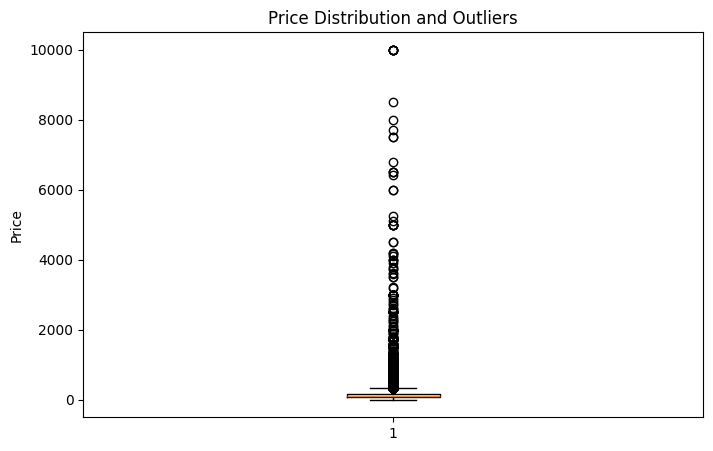

In [9]:
# ============================================================
# VISUALIZATION 1 — PRICE OUTLIER BOXPLOT
# ============================================================

import matplotlib.pyplot as plt

# Create figure size
plt.figure(figsize=(8,5))

# Create boxplot
plt.boxplot(df['price'])

# Add title
plt.title("Price Distribution and Outliers")

# Add y-axis label
plt.ylabel("Price")

# Display chart
plt.show()

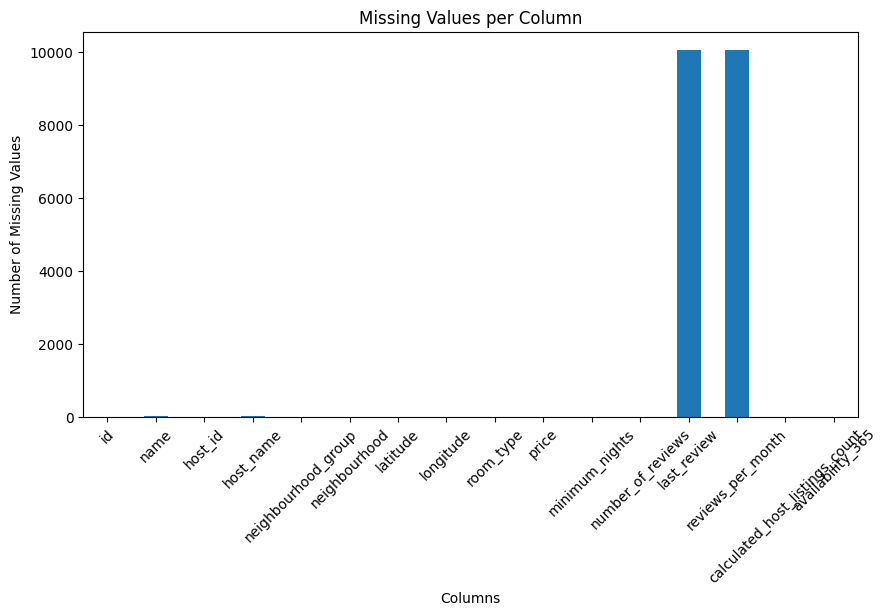

In [10]:
# ============================================================
# VISUALIZATION 2 — MISSING VALUES BAR CHART
# ============================================================

# Count missing values
missing_values = df.isnull().sum()

# Create figure
plt.figure(figsize=(10,5))

# Create bar chart
missing_values.plot(kind='bar')

# Add chart title
plt.title("Missing Values per Column")

# Add axis labels
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

# Rotate x-axis labels for readability
plt.xticks(rotation=45)

# Display chart
plt.show()

In [11]:
# ============================================================
# STEP 7A — TIMELINESS ANALYSIS
# ============================================================

# Convert last_review column into datetime format
df['last_review'] = pd.to_datetime(df['last_review'])

# ============================================================

# Find oldest review date
print("\nOLDEST REVIEW DATE")
print(df['last_review'].min())

# ============================================================

# Find most recent review date
print("\nMOST RECENT REVIEW DATE")
print(df['last_review'].max())

# ============================================================
# STEP 7B — CONSISTENCY ANALYSIS
# ============================================================

# Check room type categories
print("\nROOM TYPE CATEGORIES")
print(df['room_type'].unique())

# ============================================================

# Check neighbourhood group categories
print("\nNEIGHBOURHOOD GROUP CATEGORIES")
print(df['neighbourhood_group'].unique())


OLDEST REVIEW DATE
2011-03-28 00:00:00

MOST RECENT REVIEW DATE
2019-07-08 00:00:00

ROOM TYPE CATEGORIES
['Private room' 'Entire home/apt' 'Shared room']

NEIGHBOURHOOD GROUP CATEGORIES
['Brooklyn' 'Manhattan' 'Queens' 'Staten Island' 'Bronx']


In [12]:
print("Minimum price:", df["price"].min())
print("Maximum price:", df["price"].max())
print("Average price:", df["price"].mean())
print("Median price:", df["price"].median())

Minimum price: 0
Maximum price: 10000
Average price: 152.7206871868289
Median price: 106.0
